# Farm Household Models: Autarky, Markets, and Separation

**ECO 701: Microeconomic Theory**  
*Companion Computational Notebook*

Most economics textbooks typically present the decisions of firms and consumers in separate chapters. The firm maximizes profits subject to technological constraints, while the consumer maximizes utility subject to a budget constraint. 

In developing country agriculture, however, the primary economic actor is the **farm household**—an enterprise that operates simultaneously as a **producer** (utilizing land and labor to grow crops) and a **consumer** (consuming food and valuing leisure).

This notebook explores:
1. **The Autarkic (Chayanovian) Household:** When labor or commodity markets are absent, production and consumption decisions are **non-separable** and the household maximizes utility subject to its own production possibilities.
2. **The Separable Farm Household (Singh, Squire, and Strauss 1986; Benjamin 1992):** With complete, competitive markets for labor and output, the farm's production decision separates completely from the household's preferences.
3. **Labor Regimes:** Visualizing households that sell wage labor vs. households that hire in wage labor.


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
from ipywidgets import interact, FloatSlider

# Global default parameters
ALPHA = 0.5   # Land share in production: F(T, L) = T^alpha * L^(1-alpha)
BETA = 0.7    # Food share in utility: U(c, l) = c^beta * l^(1-beta)
TBAR = 100    # Default land endowment
LBAR = 100    # Default time endowment
W = 1.0       # Default market real wage

def F(T, L, alpha=ALPHA):
    '''Cobb-Douglas production function'''
    return (T**alpha) * (L**(1 - alpha))

def FL(T, L, alpha=ALPHA):
    '''Marginal product (shadow price) of labor'''
    return (1 - alpha) * F(T, L, alpha) / L

def FT(T, L, alpha=ALPHA):
    '''Marginal product (shadow price) of land'''
    return alpha * F(T, L, alpha) / T

def U(c, l, beta=BETA):
    '''Cobb-Douglas utility function'''
    return (c**beta) * (l**(1 - beta))

def indif(l, ubar, beta=BETA):
    '''Indifference curve: consumption as a function of leisure'''
    return (ubar / (l**(1 - beta)))**(1 / beta)

def HH_autarky(Tbar, Lbar, alpha=ALPHA, beta=BETA):
    '''Autarkic (Chayanovian) optimal leisure, output/consumption, and utility'''
    a = (1 - alpha) * beta / (1 - beta)
    l_opt = Lbar / (1 + a)
    q_opt = F(Tbar, Lbar - l_opt, alpha)
    u_opt = U(q_opt, l_opt, beta)
    return l_opt, q_opt, u_opt

def farm_optimum(Tbar, w, alpha=ALPHA):
    '''Optimal farm labor demand and profits (land rent)'''
    LD = Tbar * ((1 - alpha) / w)**(1 / alpha)
    profit = F(Tbar, LD, alpha) - w * LD
    return LD, profit

def HH_optimum(Tbar, Lbar, w, alpha=ALPHA, beta=BETA):
    '''Optimal consumption, leisure, and utility with markets'''
    _, profits = farm_optimum(Tbar, w, alpha)
    income = profits + w * Lbar
    consumption = beta * income
    leisure = (1 - beta) * income / w
    utility = U(consumption, leisure, beta)
    return consumption, leisure, utility


---

## 1. The Autarkic (Chayanovian) Household

Inspired by the Russian agricultural economist **A.V. Chayanov (1926)**, we first consider a peasant household without access to labor or commodity markets.

The household has land $\bar{T}$ and time $\bar{L}$, allocating time between on-farm work $L$ and leisure $l = \bar{L} - L$:
$$\max_{l} U\left(F(\bar{T}, \bar{L} - l),\, l\right)$$

### First-Order Condition
The household allocates labor until the **Marginal Rate of Substitution (MRS)** equals the **Marginal Product of Labor ($\text{MP}_L$)**:
$$\text{MRS}(c, l) = \text{MP}_L(L) \implies \frac{(1-\beta) c}{\beta l} = (1-\alpha) \frac{F(\bar{T}, L)}{L}$$

Substituting $c = F(\bar{T}, L)$ yields:
$$l^*_{\text{aut}} = \frac{\bar{L}}{1 + \frac{(1-\alpha)\beta}{1-\beta}}, \qquad L^*_{\text{aut}} = \bar{L} - l^*_{\text{aut}}$$

The internal **shadow wage** $w^*$ is the slope of the common tangent:
$$w^* = \text{MP}_L(\bar{T}, L^*_{\text{aut}}) = (1-\alpha) \frac{F(\bar{T}, L^*_{\text{aut}})}{L^*_{\text{aut}}}$$


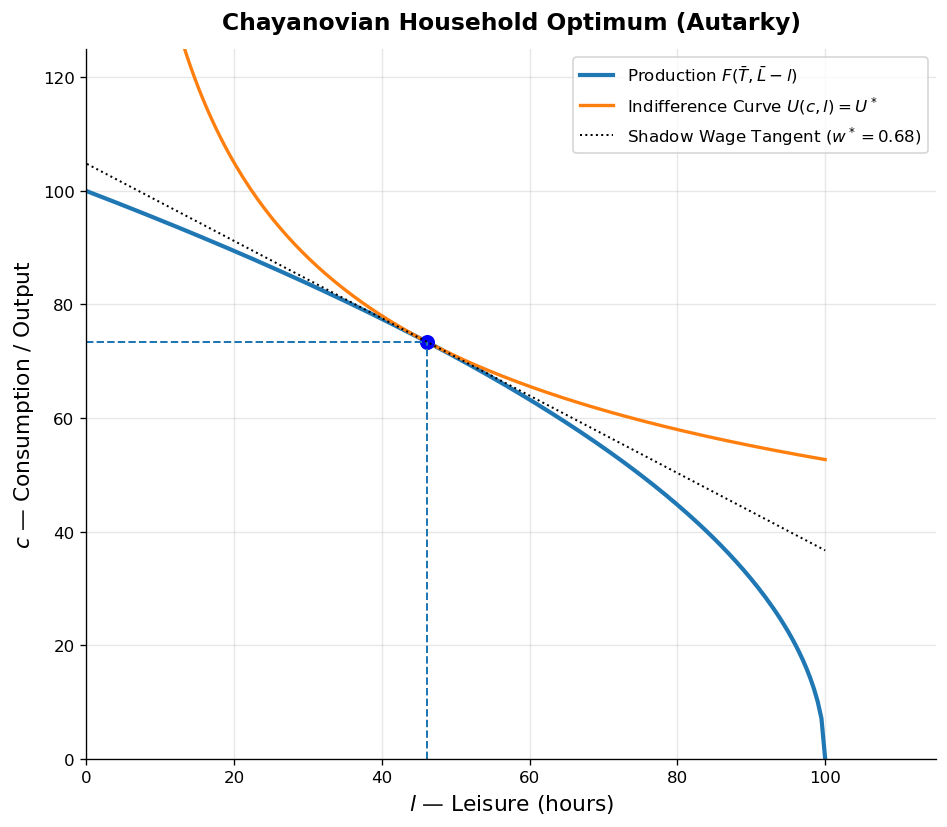

In [2]:
def chayanov(Tbar=TBAR, Lbar=LBAR, alpha=ALPHA, beta=BETA):
    leis = np.linspace(0.1, Lbar, num=200)
    q = F(Tbar, Lbar - leis, alpha)
    l_opt, Q, U_val = HH_autarky(Tbar, Lbar, alpha, beta)
    w_shadow = FL(Tbar, Lbar - l_opt, alpha)
    c_ind = indif(leis, U_val, beta)
    
    fig, ax = plt.subplots(figsize=(8, 7), dpi=120)
    ax.plot(leis, q, lw=2.5, color='#1f77b4', label=r'Production $F(\bar{T}, \bar{L}-l)$')
    ax.plot(leis, c_ind, lw=2.0, color='#ff7f0e', label=r'Indifference Curve $U(c,l)=U^*$')
    ax.plot(l_opt, Q, 'ob', markersize=8)
    
    # Dashed coordinate drop lines
    ax.vlines(l_opt, 0, Q, linestyles='dashed', color='#1f77b4', lw=1.2)
    ax.hlines(Q, 0, l_opt, linestyles='dashed', color='#1f77b4', lw=1.2)
    
    # Tangent line (slope -w*)
    tan_line = Q - w_shadow * (leis - l_opt)
    mask = (tan_line >= 0) & (tan_line <= Q * 1.5)
    ax.plot(leis[mask], tan_line[mask], 'k:', lw=1.2, label=f'Shadow Wage Tangent ($w^*={w_shadow:.2f}$)')
    
    ax.set_xlim(0, Lbar + 15)
    ax.set_ylim(0, F(Tbar, Lbar, alpha) + 25)
    ax.set_xlabel(r'$l$ — Leisure (hours)', fontsize=13)
    ax.set_ylabel(r'$c$ — Consumption / Output', fontsize=13)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.grid(True, alpha=0.3)
    ax.set_title('Chayanovian Household Optimum (Autarky)', fontsize=14, fontweight='bold', pad=12)
    ax.legend(loc='upper right', fontsize=10)
    plt.tight_layout()
    plt.show()

chayanov(TBAR, LBAR, ALPHA, BETA)


---

## 2. The Separable Farm Household with Markets

When competitive markets for labor (wage $w$) and food (price $p = 1$) exist, the farm household's decisions become **separable**:

1. **Stage 1 (Profit Maximization):** The farm operates as a price-taking enterprise, choosing labor demand $L^*$ to maximize profits:
   $$\max_{L} \Pi = F(\bar{T}, L) - w L \implies \text{MP}_L(L^*) = w$$
   $$L^*(w, \bar{T}) = \bar{T} \left(\frac{1-\alpha}{w}\right)^{1/\alpha}, \qquad \Pi^*(w, \bar{T}) = F(\bar{T}, L^*) - w L^*$$
   *Crucially, $L^*$ and $\Pi^*$ depend strictly on $(T, w)$—independent of preferences $\beta$ or family size $\bar{L}$.*

2. **Stage 2 (Utility Maximization):** The household maximizes utility subject to its full-income budget line:
   $$\max_{c, l} U(c, l) \quad \text{s.t.} \quad c + w l \le \Pi^*(w, \bar{T}) + w \bar{L}$$
   $$c^* = \beta (\Pi^* + w \bar{L}), \qquad l^* = \frac{(1-\beta)(\Pi^* + w \bar{L})}{w}$$


In [3]:
def plot_production(Tbar, Lbar, w, ax):
    lei = np.linspace(1, Lbar, 200)
    q = F(Tbar, Lbar - lei)
    ax.plot(lei, q, lw=2.5, color='#00558f')
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

def plot_farmconsumption(Tbar, Lbar, w, ax, alpha=ALPHA, beta=BETA):
    lei = np.linspace(1, Lbar, 200)
    LD, profits = farm_optimum(Tbar, w, alpha)
    q_opt = F(Tbar, LD, alpha)
    yline = profits + w * Lbar - w * lei
    c_opt, l_opt, u_opt = HH_optimum(Tbar, Lbar, w, alpha, beta)
    
    # Plot curves
    ax.plot(Lbar - LD, q_opt, 'ob', markersize=7) 
    ax.plot(lei, yline, color='#d95f02', lw=2.0)  
    ax.plot(lei, indif(lei, u_opt, beta), 'k', lw=1.8)
    ax.plot(l_opt, c_opt, 'ob', markersize=7)
    
    # Dashed reference lines
    ax.vlines(l_opt, 0, c_opt, linestyles='dashed', color='#00558f', lw=1.2)
    ax.hlines(c_opt, 0, l_opt, linestyles='dashed', color='#00558f', lw=1.2)
    ax.vlines(Lbar - LD, 0, q_opt, linestyles='dashed', color='#00558f', lw=1.2)
    ax.hlines(profits, 0, Lbar, linestyles='dashed', color='#00558f', lw=1.2)
    ax.vlines(Lbar, 0, F(Tbar, Lbar, alpha), color='#00558f', lw=2.0)
    ax.hlines(q_opt, 0, Lbar, linestyles='dashed', color='#00558f', lw=1.2)
    
    # Text labels on right axis and left axis
    ax.text(Lbar + 1.5, profits, r'$\Pi ^*$', fontsize=16, va='center')
    ax.text(Lbar + 1.5, q_opt, r'$F(\bar T, L^{*})$', fontsize=16, va='center')
    ax.text(-5, c_opt, r'$c^*$', fontsize=16, ha='right', va='center')
    
    # Bottom arrows for L* and l*
    ax.annotate('', (Lbar - LD, 2), (Lbar, 2), arrowprops=dict(arrowstyle='->', lw=1.2, color='black'))
    ax.text((2 * Lbar - LD) / 2, 4, r'$L^{*}$', fontsize=16, ha='center')
    
    ax.annotate('', (0, 7), (l_opt, 7), arrowprops=dict(arrowstyle='<-', lw=1.2, color='black'))
    ax.text(l_opt / 2, 9, r'$l^*$', fontsize=16, ha='center')


---

## 3. Case 1: Household Sells Wage Labor and Buys Food

When the market real wage is relatively high ($w = 1.0$), optimal farm labor demand is $L^* = 25\text{h}$. 

Family labor supply is $L^s = \bar{L} - l^* = 100 - 37.5 = 62.5\text{h}$. The household:
* Works $25\text{h}$ on its own farm.
* **Hires out (sells) $37.5\text{h}$ of surplus labor** on the off-farm labor market.
* Uses wage income to purchase additional food on the market ($c^* = 87.5 > F(\bar{T}, L^*) = 50$).


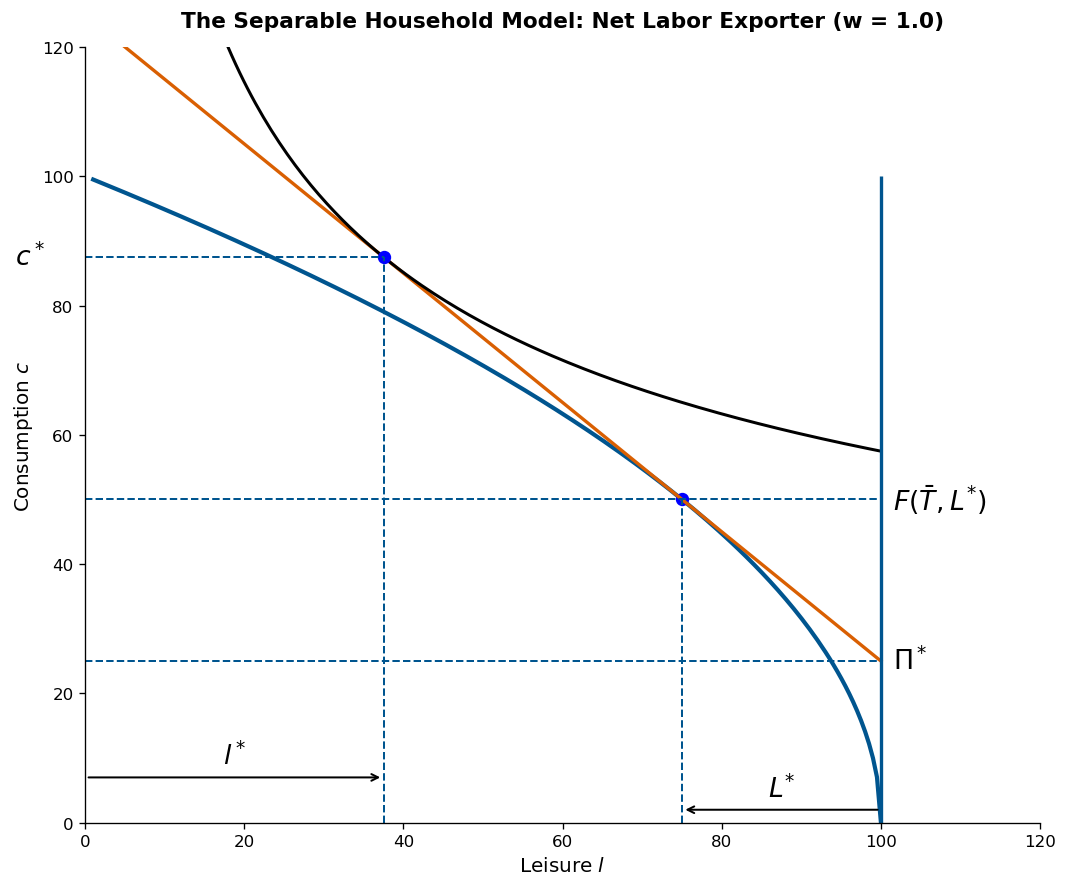

In [4]:
fig, ax = plt.subplots(figsize=(9, 7.5), dpi=120)
plot_production(TBAR, LBAR, W, ax)
plot_farmconsumption(TBAR, LBAR, W, ax)
ax.set_title("The Separable Household Model: Net Labor Exporter (w = 1.0)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlim(0, LBAR + 20)
ax.set_ylim(0, F(TBAR, LBAR) + 20)
ax.set_xlabel(r'Leisure $l$', fontsize=12)
ax.set_ylabel(r'Consumption $c$', fontsize=12)
plt.tight_layout()
plt.show()


---

## 4. Case 2: Household Hires Wage Labor and Sells Food

When the market real wage is lower ($w = 0.55$), the farm's labor demand expands to $L^* = 82.6\text{h}$.

Family labor supply is $L^s = \bar{L} - l^* = 100 - 54.8 = 45.2\text{h}$. The household:
* Devotes all $45.2\text{h}$ of family labor to the farm.
* **Hires in $37.4\text{h}$ of outside hired labor**.
* **Sells surplus crop output** on the market ($F(\bar{T}, L^*) = 90.9 > c^* = 67.5$).


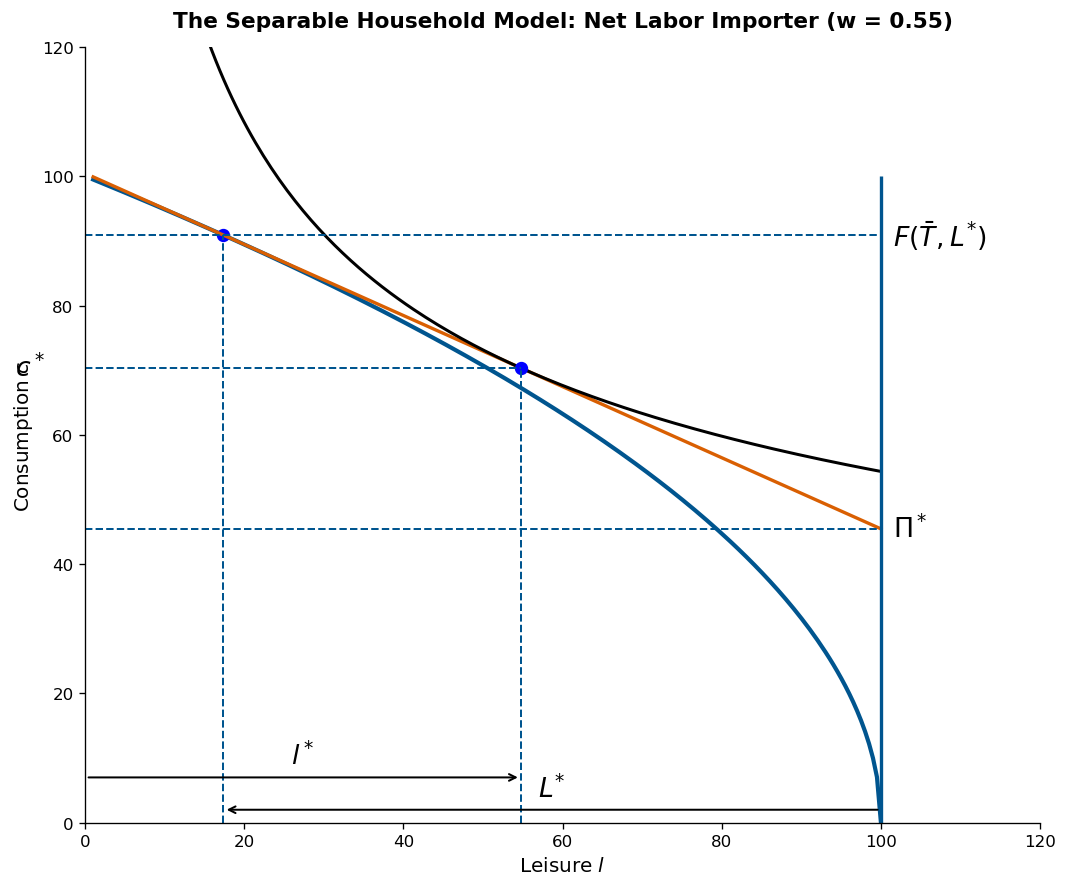

In [5]:
fig, ax = plt.subplots(figsize=(9, 7.5), dpi=120)
plot_production(TBAR, LBAR, W * 0.55, ax)
plot_farmconsumption(TBAR, LBAR, W * 0.55, ax)
ax.set_title("The Separable Household Model: Net Labor Importer (w = 0.55)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlim(0, LBAR + 20)
ax.set_ylim(0, F(TBAR, LBAR) + 20)
ax.set_xlabel(r'Leisure $l$', fontsize=12)
ax.set_ylabel(r'Consumption $c$', fontsize=12)
plt.tight_layout()
plt.show()


---

## 5. Summary: Key Theoretical Takeaways

| Dimension | Autarkic (Chayanovian) Model | Separable Market Model |
| :--- | :--- | :--- |
| **Separability** | **Non-separable:** Production depends on consumer preferences $\beta$ and time endowment $\bar{L}$. | **Separable:** Production $L^*$ depends only on technology $(A, \alpha)$, land $\bar{T}$, and wage $w$. |
| **Labor Allocation** | Determined by household utility maximization against farm production frontier. | Determined by profit maximization ($\text{MP}_L = w$). |
| **Labor Market Status** | Autarkic (self-sufficient; no hiring in or out). | Net labor exporter ($L^* < L^s$) or Net labor importer ($L^* > L^s$). |
| **Price / Policy Response** | Ambiguous response to food price changes. | **Deaton (1989):** Welfare change $\Delta W \approx (Q^* - c^*) \Delta p$. Net sellers gain; net buyers lose. |
